In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_columns", None)

In [38]:
df = pd.read_csv("airline_tweets.csv")


df_stage2 = df.copy()

print("Dataset shape:", df_stage2.shape)
display(df_stage2.head())

Dataset shape: (370863, 7)


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id
0,332,AirAsiaSupport,False,Tue Oct 31 22:12:55 +0000 2017,"@115797 Hi Loreen,kindly DM us your booking number and attach guest passport copy, we'll fix it for you, see you the...",333,334.0
1,333,115797,True,Tue Oct 31 23:44:59 +0000 2017,@AirAsiaSupport Hi! I have DM u my booking # and passport picture thanks so much for quick action,335,332.0
2,335,AirAsiaSupport,False,Tue Oct 31 23:57:53 +0000 2017,"@115797 Hi Loreen,correction done! :) See you on board! Cheers!- Anwar","336,337",333.0
3,336,115797,True,Wed Nov 01 00:01:49 +0000 2017,@AirAsiaSupport thank you very much..,NaN,335.0
4,337,115797,True,Thu Nov 09 20:15:48 +0000 2017,@AirAsiaSupport Hi! i would like to know on my itenerary on how the birthday can be seen. i would like to double che...,338,335.0


Check and prepare the columns

In [39]:
required_columns = [
    "tweet_id",
    "author_id",
    "inbound",
    "created_at",
    "text",
    "response_tweet_id",
    "in_response_to_tweet_id"
]

missing_columns = [
    col for col in required_columns
    if col not in df_stage2.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# IDs should be strings, not numbers
id_columns = [
    "tweet_id",
    "author_id",
    "response_tweet_id",
    "in_response_to_tweet_id"
]

for col in id_columns:
    df_stage2[col] = df_stage2[col].astype("string").str.strip()

# Convert timestamps to datetime
df_stage2["created_at"] = pd.to_datetime(
    df_stage2["created_at"],
    errors="coerce",
    utc=True
)

# Ensure inbound is Boolean
df_stage2["inbound"] = (
    df_stage2["inbound"]
    .astype(str)
    .str.lower()
    .map({"true": True, "false": False})
)

# Remove rows without a usable tweet ID
df_stage2 = df_stage2.dropna(subset=["tweet_id"])

print("Preparation complete!")
print(df_stage2.dtypes)

/tmp/ipykernel_8482/2857772059.py:31: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_stage2["created_at"] = pd.to_datetime(


Preparation complete!
tweet_id                        string[python]
author_id                       string[python]
inbound                                   bool
created_at                 datetime64[ns, UTC]
text                                    object
response_tweet_id               string[python]
in_response_to_tweet_id         string[python]
dtype: object


Create message categories

In [40]:
df_stage2["message_type"] = np.where(
    df_stage2["inbound"] == True,
    "Customer",
    "Airline Support"
)

display(df_stage2["message_type"].value_counts())

message_type
Customer           198017
Airline Support    172846
Name: count, dtype: int64

Reconstruct direct replies

In [41]:
# Separate customer and airline messages
customers = df_stage2[
    df_stage2["message_type"] == "Customer"
].copy()

airline_replies = df_stage2[
    df_stage2["message_type"] == "Airline Support"
].copy()

# Rename columns to distinguish original messages from replies
customer_messages = customers[
    ["tweet_id", "author_id", "created_at", "text"]
].rename(columns={
    "tweet_id": "customer_tweet_id",
    "author_id": "customer_id",
    "created_at": "customer_time",
    "text": "customer_text"
})

support_messages = airline_replies[
    ["tweet_id", "author_id", "created_at",
     "text", "in_response_to_tweet_id"]
].rename(columns={
    "tweet_id": "support_tweet_id",
    "author_id": "airline",
    "created_at": "support_time",
    "text": "support_text",
    "in_response_to_tweet_id": "parent_tweet_id"
})

# Connect airline replies to their original customer messages
conversation_pairs = customer_messages.merge(
    support_messages,
    left_on="customer_tweet_id",
    right_on="parent_tweet_id",
    how="inner"
)

print("Customer-support reply pairs:", len(conversation_pairs))

display(
    conversation_pairs[
        [
            "customer_tweet_id",
            "customer_text",
            "airline",
            "support_text"
        ]
    ].head(10)
)

Customer-support reply pairs: 0


,customer_tweet_id,customer_text,airline,support_text


Calculate response time

In [42]:
conversation_pairs["response_time_minutes"] = (
    conversation_pairs["support_time"]
    - conversation_pairs["customer_time"]
).dt.total_seconds() / 60

display(
    conversation_pairs[
        [
            "customer_tweet_id",
            "airline",
            "response_time_minutes"
        ]
    ].head(10)
)

,customer_tweet_id,airline,response_time_minutes


In [43]:
valid_responses = conversation_pairs[
    conversation_pairs["response_time_minutes"].notna()
    & (conversation_pairs["response_time_minutes"] >= 0)
].copy()

print("Valid response pairs:", len(valid_responses))

print(
    "Average response time:",
    round(valid_responses["response_time_minutes"].mean(), 2),
    "minutes"
)

print(
    "Median response time:",
    round(valid_responses["response_time_minutes"].median(), 2),
    "minutes"
)

Valid response pairs: 0
Average response time: nan minutes
Median response time: nan minutes


In [44]:
airline_response_analysis = (
    valid_responses
    .groupby("airline")
    .agg(
        total_replies=("support_tweet_id", "count"),
        average_response_minutes=("response_time_minutes", "mean"),
        median_response_minutes=("response_time_minutes", "median")
    )
    .sort_values("median_response_minutes")
)

display(airline_response_analysis)

,total_replies,average_response_minutes,median_response_minutes
airline,,,


IndexError: index 0 is out of bounds for axis 0 with size 0

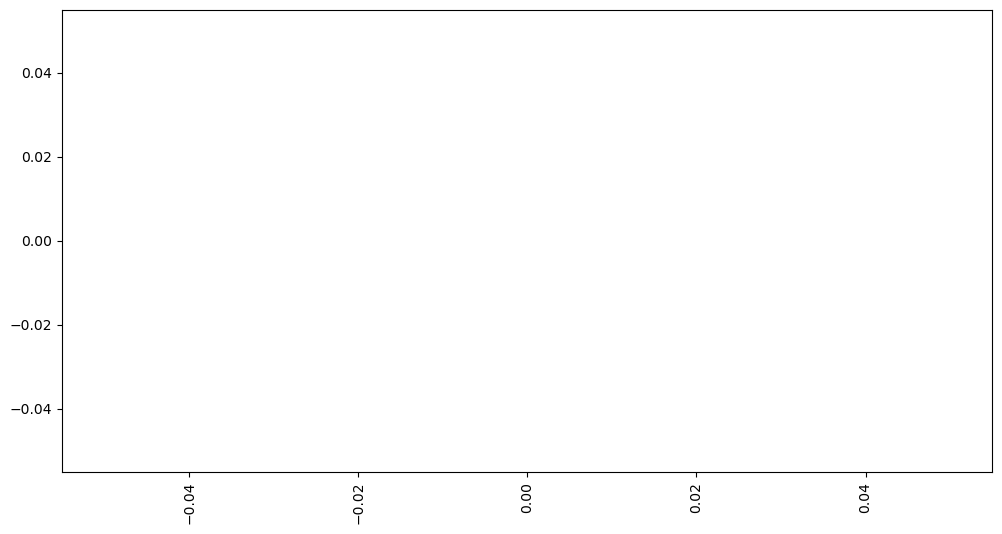

In [45]:
airline_response_analysis["median_response_minutes"].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Median Customer Response Time by Airline")
plt.xlabel("Airline")
plt.ylabel("Response Time (Minutes)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [46]:
replied_customer_ids = set(
    valid_responses["customer_tweet_id"].dropna()
)

df_stage2["has_airline_response"] = (
    (df_stage2["message_type"] == "Customer")
    & df_stage2["tweet_id"].isin(replied_customer_ids)
)

# Select customer messages without a linked direct airline reply
unanswered_customers = df_stage2[
    (df_stage2["message_type"] == "Customer")
    & (~df_stage2["has_airline_response"])
].copy()

answered_customers = df_stage2[
    df_stage2["has_airline_response"]
].copy()

print("Customer messages:", len(customers))
print("Customer messages with linked replies:", len(answered_customers))
print("Customer messages without linked replies:", len(unanswered_customers))

Customer messages: 198017
Customer messages with linked replies: 0
Customer messages without linked replies: 198017


In [47]:
import os

os.makedirs("../data/processed", exist_ok=True)

df_stage2.to_csv(
    "../data/processed/airline_messages_processed.csv",
    index=False
)

conversation_pairs.to_csv(
    "../data/processed/customer_support_conversations.csv",
    index=False
)

valid_responses.to_csv(
    "../data/processed/valid_response_times.csv",
    index=False
)

unanswered_customers.to_csv(
    "../data/processed/unanswered_customer_messages.csv",
    index=False
)

print("Stage 2 processing completed!")

Stage 2 processing completed!


In [48]:
print("Sample size:", df_stage2.shape)

print("\nConversation pairs:", len(conversation_pairs))

print("\nValid response pairs:", len(valid_responses))

print("\nResponse time summary:")
print(valid_responses["response_time_minutes"].describe())

print("\nAirline response analysis:")
display(airline_response_analysis)

print("\nUnanswered customer messages:", len(unanswered_customers))

Sample size: (370863, 9)

Conversation pairs: 0

Valid response pairs: 0

Response time summary:
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: response_time_minutes, dtype: float64

Airline response analysis:


,total_replies,average_response_minutes,median_response_minutes
airline,,,



Unanswered customer messages: 198017


inspect

In [49]:
id_columns = [
    "tweet_id",
    "response_tweet_id",
    "in_response_to_tweet_id"
]

print("ID column data types:")
print(df_stage2[id_columns].dtypes)

print("\nExample tweet IDs:")
display(df_stage2[id_columns].head(15))

print("\nNumber of missing IDs:")
print(df_stage2[id_columns].isna().sum())

ID column data types:
tweet_id                   string[python]
response_tweet_id          string[python]
in_response_to_tweet_id    string[python]
dtype: object

Example tweet IDs:


,tweet_id,response_tweet_id,in_response_to_tweet_id
0,332,333,334.0
1,333,335,332.0
2,335,"336,337",333.0
3,336,<NA>,335.0
4,337,338,335.0
5,338,339,337.0
6,339,340,338.0
7,340,341,339.0
8,341,342,340.0
9,342,<NA>,341.0



Number of missing IDs:
tweet_id                        0
response_tweet_id          146435
in_response_to_tweet_id    108869
dtype: int64


In [50]:
customer_ids = set(
    df_stage2.loc[
        df_stage2["inbound"] == True, "tweet_id"
    ].dropna().astype(str)
)

support_parent_ids = set(
    df_stage2.loc[
        df_stage2["inbound"] == False,
        "in_response_to_tweet_id"
    ].dropna().astype(str)
)

print("Unique customer IDs:", len(customer_ids))
print("Unique support parent IDs:", len(support_parent_ids))
print("Matching IDs:", len(customer_ids.intersection(support_parent_ids)))

print("\nCustomer ID examples:")
print(list(customer_ids)[:5])

print("\nSupport parent ID examples:")
print(list(support_parent_ids)[:5])

Unique customer IDs: 198017
Unique support parent IDs: 157074
Matching IDs: 0

Customer ID examples:
['2385759', '796639', '2041834', '2293745', '1238835']

Support parent ID examples:
['463605.0', '659692.0', '2060211.0', '329443.0', '2140149.0']


In [51]:
customers = df_stage2[
    df_stage2["inbound"] == True
].copy()

support = df_stage2[
    df_stage2["inbound"] == False
].copy()

customer_messages = customers[
    ["tweet_id", "author_id", "created_at", "text"]
].rename(columns={
    "tweet_id": "customer_tweet_id",
    "author_id": "customer_id",
    "created_at": "customer_time",
    "text": "customer_text"
})

support_messages = support[
    ["tweet_id", "author_id", "created_at",
     "text", "in_response_to_tweet_id"]
].rename(columns={
    "tweet_id": "support_tweet_id",
    "author_id": "airline",
    "created_at": "support_time",
    "text": "support_text",
    "in_response_to_tweet_id": "parent_tweet_id"
})

conversation_pairs = customer_messages.merge(
    support_messages,
    left_on="customer_tweet_id",
    right_on="parent_tweet_id",
    how="inner"
)

print("Conversation pairs:", len(conversation_pairs))
display(conversation_pairs.head())

Conversation pairs: 0


,customer_tweet_id,customer_id,customer_time,customer_text,support_tweet_id,airline,support_time,support_text,parent_tweet_id


In [52]:
id_columns = [
    "tweet_id",
    "response_tweet_id",
    "in_response_to_tweet_id"
]

def normalize_id(series):
    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .replace("", pd.NA)
    )

for col in id_columns:
    df_stage2[col] = normalize_id(df_stage2[col])

display(df_stage2[id_columns].head(15))

,tweet_id,response_tweet_id,in_response_to_tweet_id
0,332,333,334
1,333,335,332
2,335,"336,337",333
3,336,<NA>,335
4,337,338,335
5,338,339,337
6,339,340,338
7,340,341,339
8,341,342,340
9,342,<NA>,341


In [53]:
customer_ids = set(
    df_stage2.loc[
        df_stage2["inbound"] == True, "tweet_id"
    ].dropna()
)

support_parent_ids = set(
    df_stage2.loc[
        df_stage2["inbound"] == False,
        "in_response_to_tweet_id"
    ].dropna()
)

matching_ids = customer_ids.intersection(support_parent_ids)

print("Unique customer IDs:", len(customer_ids))
print("Unique support parent IDs:", len(support_parent_ids))
print("Matching IDs:", len(matching_ids))

Unique customer IDs: 198017
Unique support parent IDs: 157074
Matching IDs: 154370


In [54]:
customers = df_stage2[
    df_stage2["inbound"] == True
].copy()

support = df_stage2[
    df_stage2["inbound"] == False
].copy()

customer_messages = customers[
    ["tweet_id", "author_id", "created_at", "text"]
].rename(columns={
    "tweet_id": "customer_tweet_id",
    "author_id": "customer_id",
    "created_at": "customer_time",
    "text": "customer_text"
})

support_messages = support[
    ["tweet_id", "author_id", "created_at",
     "text", "in_response_to_tweet_id"]
].rename(columns={
    "tweet_id": "support_tweet_id",
    "author_id": "airline",
    "created_at": "support_time",
    "text": "support_text",
    "in_response_to_tweet_id": "parent_tweet_id"
})

conversation_pairs = customer_messages.merge(
    support_messages,
    left_on="customer_tweet_id",
    right_on="parent_tweet_id",
    how="inner"
)

print("Reconstructed conversations:", len(conversation_pairs))

display(
    conversation_pairs[
        [
            "customer_text",
            "support_text",
            "airline"
        ]
    ].head(10)
)

Reconstructed conversations: 169344


,customer_text,support_text,airline
0,@AirAsiaSupport Hi! I have DM u my booking # and passport picture thanks so much for quick action,"@115797 Hi Loreen,correction done! :) See you on board! Cheers!- Anwar",AirAsiaSupport
1,@AirAsiaSupport Hi! i would like to know on my itenerary on how the birthday can be seen. i would like to double che...,"@115797 Hi Loreen, you may check the passenger's date of birth via AirAsia member account under manage booking. Than...",AirAsiaSupport
2,@AirAsiaSupport but i cant see it. i only see itenerary.. no birthday,@115797 As you may check it under manage my booking online or during web check in. Date of birth will be shown accor...,AirAsiaSupport
3,@AirAsiaSupport Hi Airasia. i want to rebook my return flight. but when i try rebooking my inbond also is rebooking....,@115797 Hi Loreen :) Kindly DM us the booking number that you wish to do change flight for us to assist you further-...,AirAsiaSupport
4,@AirAsiaSupport hi! I have booked my ticket and when i see my itenary has been redundant i call ur customer service...,"@115797 Hi Loreen,kindly DM us your booking number and attach guest passport copy, we'll fix it for you, see you the...",AirAsiaSupport
5,@AirAsiaSupport lost my booking # chua loreen lee flight z2 129.128 12/22-01/8 taipei-manila. __email__,@115797 Sorry as we checked booking has already expired due to no payment made. Kindly please proceed with new booki...,AirAsiaSupport
6,"@AirAsiaSupport Hi Yana, followed!","@115799 Hi Emma, We have replied to you via DM. please check again, Thank you- Mariya",AirAsiaSupport
7,@AirAsiaSupport Hi Yana I don’t have any DMs from you. Did you mean email?,"@115799 Hi Emma, Could you please follow us so we can DM you again with the email reply sent to you =) Yana",AirAsiaSupport
8,@AirAsiaSupport CAS-19708536-CB92N2 CRM:0326600 Please check on this I haven't heard from my case officer in weeks a...,@115799 We have replied to you via DM. Check it out =) Yana,AirAsiaSupport
9,@115801 @115802 @AirAsiaSupport You'll be even happier to know that the restrictions around the volcano area have be...,@115800 notified if there should be any changes-Yana,AirAsiaSupport


In [55]:
conversation_pairs["response_time_minutes"] = (
    conversation_pairs["support_time"]
    - conversation_pairs["customer_time"]
).dt.total_seconds() / 60

valid_responses = conversation_pairs[
    conversation_pairs["response_time_minutes"].notna()
    & (conversation_pairs["response_time_minutes"] >= 0)
].copy()

print(valid_responses["response_time_minutes"].describe())

count    1.693440e+05
mean     1.414730e+02
std      8.995666e+03
min      3.333333e-02
25%      4.100000e+00
50%      1.346667e+01
75%      5.968333e+01
max      2.609747e+06
Name: response_time_minutes, dtype: float64


In [56]:
print("Matching IDs:", len(matching_ids))
print("Conversation pairs:", len(conversation_pairs))
print("Valid response pairs:", len(valid_responses))

display(conversation_pairs.head(5))

Matching IDs: 154370
Conversation pairs: 169344
Valid response pairs: 169344


,customer_tweet_id,customer_id,customer_time,customer_text,support_tweet_id,airline,support_time,support_text,parent_tweet_id,response_time_minutes
0,333,115797,2017-10-31 23:44:59+00:00,@AirAsiaSupport Hi! I have DM u my booking # and passport picture thanks so much for quick action,335,AirAsiaSupport,2017-10-31 23:57:53+00:00,"@115797 Hi Loreen,correction done! :) See you on board! Cheers!- Anwar",333,12.900000
1,337,115797,2017-11-09 20:15:48+00:00,@AirAsiaSupport Hi! i would like to know on my itenerary on how the birthday can be seen. i would like to double che...,338,AirAsiaSupport,2017-11-10 06:43:03+00:00,"@115797 Hi Loreen, you may check the passenger's date of birth via AirAsia member account under manage booking. Than...",337,627.250000
2,339,115797,2017-11-10 18:03:05+00:00,@AirAsiaSupport but i cant see it. i only see itenerary.. no birthday,340,AirAsiaSupport,2017-11-11 13:06:21+00:00,@115797 As you may check it under manage my booking online or during web check in. Date of birth will be shown accor...,339,1143.266667
3,341,115797,2017-11-16 19:21:34+00:00,@AirAsiaSupport Hi Airasia. i want to rebook my return flight. but when i try rebooking my inbond also is rebooking....,342,AirAsiaSupport,2017-11-17 07:48:10+00:00,@115797 Hi Loreen :) Kindly DM us the booking number that you wish to do change flight for us to assist you further-...,341,746.600000
4,334,115797,2017-10-31 14:31:46+00:00,@AirAsiaSupport hi! I have booked my ticket and when i see my itenary has been redundant i call ur customer service...,332,AirAsiaSupport,2017-10-31 22:12:55+00:00,"@115797 Hi Loreen,kindly DM us your booking number and attach guest passport copy, we'll fix it for you, see you the...",334,461.150000


Response-time statistics

In [57]:
print("Response time statistics (minutes):")

display(
    valid_responses["response_time_minutes"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

Response time statistics (minutes):


count    1.693440e+05
mean     1.414730e+02
std      8.995666e+03
min      3.333333e-02
25%      4.100000e+00
50%      1.346667e+01
75%      5.968333e+01
90%      2.483167e+02
95%      4.728475e+02
99%      9.429237e+02
max      2.609747e+06
Name: response_time_minutes, dtype: float64

Convert minutes into hours

In [58]:
valid_responses["response_time_hours"] = (
    valid_responses["response_time_minutes"] / 60
)

print(
    "Average response time:",
    round(valid_responses["response_time_hours"].mean(), 2),
    "hours"
)

print(
    "Median response time:",
    round(valid_responses["response_time_hours"].median(), 2),
    "hours"
)

Average response time: 2.36 hours
Median response time: 0.22 hours


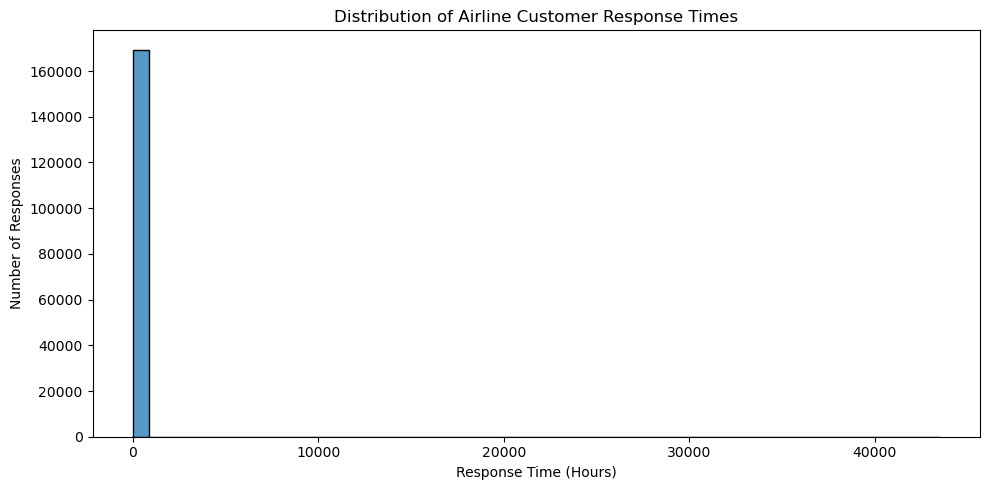

In [59]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=valid_responses,
    x="response_time_hours",
    bins=50
)

plt.title("Distribution of Airline Customer Response Times")
plt.xlabel("Response Time (Hours)")
plt.ylabel("Number of Responses")
plt.tight_layout()
plt.show()

Compare airline performance

In [60]:
airline_response_analysis = (
    valid_responses
    .groupby("airline")
    .agg(
        total_replies=("support_tweet_id", "count"),
        unique_customers=("customer_tweet_id", "nunique"),
        average_response_minutes=("response_time_minutes", "mean"),
        median_response_minutes=("response_time_minutes", "median")
    )
    .sort_values("median_response_minutes")
)

display(airline_response_analysis)

,total_replies,unique_customers,average_response_minutes,median_response_minutes
airline,,,,
GWRHelp,2,2,1.941667,1.941667
VirginTrains,16,15,3.960417,3.166667
VMUcare,1,1,3.283333,3.283333
AlaskaAir,7119,7051,9.320759,3.516667
JetBlue,7726,6952,76.314919,3.566667
VirginAmerica,2675,2647,12.951072,3.666667
ArgosHelpers,1,1,5.550000,5.550000
SouthwestAir,28492,27951,29.088893,6.900000
Delta,41520,35646,171.840653,10.116667


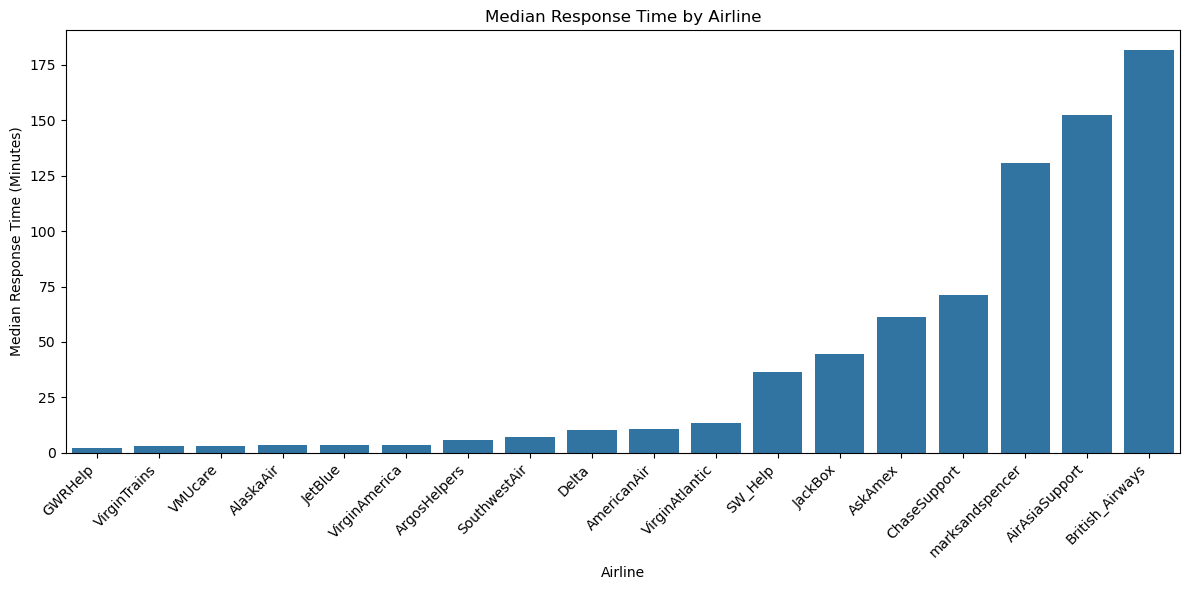

In [61]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=airline_response_analysis.reset_index(),
    x="airline",
    y="median_response_minutes"
)

plt.title("Median Response Time by Airline")
plt.xlabel("Airline")
plt.ylabel("Median Response Time (Minutes)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Calculate unanswered customer messages correctly

In [62]:
replied_customer_ids = set(
    valid_responses["customer_tweet_id"].dropna()
)

unanswered_customers = customers[
    ~customers["tweet_id"].isin(replied_customer_ids)
].copy()

answered_customer_count = customers[
    "tweet_id"
].isin(replied_customer_ids).sum()

print("Total customer messages:", len(customers))
print("Customer messages with replies:", answered_customer_count)
print("Customer messages without linked replies:", len(unanswered_customers))

Total customer messages: 198017
Customer messages with replies: 154370
Customer messages without linked replies: 43647


In [63]:
import os

os.makedirs("../data/processed", exist_ok=True)

conversation_pairs.to_csv(
    "../data/processed/customer_support_conversations.csv",
    index=False
)

valid_responses.to_csv(
    "../data/processed/valid_response_times.csv",
    index=False
)

unanswered_customers.to_csv(
    "../data/processed/unanswered_customer_messages.csv",
    index=False
)

airline_response_analysis.to_csv(
    "../data/processed/airline_response_analysis.csv"
)

- 77.96% have at least one linked airline response.
- 22.04% have no linked response in the dataset.
These are linkage statistics, not proof that airlines ignored 22.04% of customers.

AlaskaAir, JetBlue and VirginAmerica have relatively short median response times in this dataset. AirAsiaSupport and British Airways have considerably longer medians.

However, this is not yet a definitive airline ranking. We need to investigate extreme delays and ensure that the comparison uses genuine airline accounts. Also, response times alone do not measure the quality of the support provided.



restrict the comparison to the main airline accounts in your results.

In [64]:
airline_accounts = [
    "AlaskaAir",
    "JetBlue",
    "VirginAmerica",
    "SouthwestAir",
    "Delta",
    "AmericanAir",
    "VirginAtlantic",
    "AirAsiaSupport",
    "British_Airways"
]

airline_only = valid_responses[
    valid_responses["airline"].isin(airline_accounts)
].copy()

airline_comparison = (
    airline_only
    .groupby("airline")
    .agg(
        total_replies=("support_tweet_id", "count"),
        unique_customers=("customer_tweet_id", "nunique"),
        median_response_minutes=("response_time_minutes", "median"),
        average_response_minutes=("response_time_minutes", "mean")
    )
    .sort_values("median_response_minutes")
)

display(airline_comparison)

,total_replies,unique_customers,median_response_minutes,average_response_minutes
airline,,,,
AlaskaAir,7119,7051,3.516667,9.320759
JetBlue,7726,6952,3.566667,76.314919
VirginAmerica,2675,2647,3.666667,12.951072
SouthwestAir,28492,27951,6.900000,29.088893
Delta,41520,35646,10.116667,171.840653
AmericanAir,36443,36369,10.716667,18.681923
VirginAtlantic,4162,4060,13.291667,43.434903
AirAsiaSupport,12007,10136,152.166667,585.470742
British_Airways,29173,23973,181.466667,254.052232


Investigate the extreme response times

In [65]:
longest_delays = valid_responses.nlargest(
    10,
    "response_time_minutes"
)

display(
    longest_delays[
        [
            "airline",
            "customer_time",
            "support_time",
            "response_time_minutes",
            "customer_text",
            "support_text"
        ]
    ]
)

,airline,customer_time,support_time,response_time_minutes,customer_text,support_text
132695,Delta,2012-11-27 11:37:19+00:00,2017-11-13 19:24:09+00:00,2.609747e+06,Thanks for the birthday present @delta ! Nothing beats a surprise 1st class upgrade as I board a 6am flight ! http:...,@680499 Welcome aboard! Thanks for flying Delta. *AJR
110328,Delta,2012-11-27 11:32:15+00:00,2017-10-29 20:11:14+00:00,2.588199e+06,@delta I wish you made it more pleasant to check into a full flight. It's stressful enough. #deltaairlines,"@576959 Hi Christine, we sincerely appreciate you providing your feedback. I will definitely forward this on for rev..."
117829,Delta,2017-05-23 21:02:17+00:00,2017-11-08 07:06:53+00:00,2.425246e+05,@Delta you lost a bag on the way there after 2 redirects. Iost bag on the way BACK and FLIGHT WAS DELAYED. I think I...,@618900 ...assistance you were seeking that we didn't provide. Thank you for tweeting us! *ABN 2/2
117830,Delta,2017-05-23 21:02:17+00:00,2017-11-08 07:06:52+00:00,2.425246e+05,@Delta you lost a bag on the way there after 2 redirects. Iost bag on the way BACK and FLIGHT WAS DELAYED. I think I...,"@618900 We're sorry our accommodations didn't meet your needs, Afsara. We provided seating together, as requested. N..."
135609,Delta,2017-07-26 11:40:08+00:00,2017-11-14 16:06:14+00:00,1.601061e+05,It’s here! My 1st int'l city guide. Sharing more about my @Delta flight &amp; trip to Dublin: https://t.co/OchzgIWSw...,@692761 Thanks for sharing! Such a great meal selection. Tweet us if you need us. *AJZ
26485,Delta,2017-10-13 09:47:10+00:00,2017-12-01 16:46:22+00:00,7.097920e+04,"@Delta so are you saying you can't find my case? I would like an answer to my complaint please, I have been waiting ...",@179076 I apologize for the delay in responding. I'll reach out to the team to find out where your case stands. Than...
21061,JetBlue,2017-06-06 08:39:53+00:00,2017-07-15 09:04:55+00:00,5.618503e+04,@JetBlue Thanks :),@210290 The future is now. :-) https://t.co/kG4sdXQgrv
52691,JetBlue,2017-09-20 13:54:36+00:00,2017-10-21 19:29:30+00:00,4.497490e+04,@JetBlue when will you release fares for August 2018,"@344873 ...through September 04, 2018. 😊 2/2"
52692,JetBlue,2017-09-20 13:54:36+00:00,2017-10-21 19:29:29+00:00,4.497488e+04,@JetBlue when will you release fares for August 2018,"@344873 Good news, Erika! Our next schedule extension will be Sunday, November 12, 2017 at 2:00 PM ET. We'll be sell..."
52689,JetBlue,2017-09-21 16:45:20+00:00,2017-10-21 19:36:58+00:00,4.337163e+04,@JetBlue how soon will flight schedules for August 2018 be released?,"@344869 ...through September 04, 2018. 😊 2/2"


What does this tell us?
- AlaskaAir has the lowest median response time, approximately 3.5 minutes.
- JetBlue has a similar median, but its average is much higher. This suggests some unusually long delays.
- Delta has a median of about 10 minutes but an average of nearly 3 hours. Its average is being pulled upwards by extreme delays.
- AirAsiaSupport and British_Airways have substantially higher median response times than the other airlines in this comparison.

Identify the first response


This gives us one first response per customer message with a linked reply.

In [66]:
# Sort responses by customer message and response time
first_responses = valid_responses.sort_values(
    by=["customer_tweet_id", "support_time"]
)

# Keep only the earliest support response per customer message
first_responses = first_responses.drop_duplicates(
    subset="customer_tweet_id",
    keep="first"
).copy()

print("Total first responses:", len(first_responses))
print(
    "Unique customer messages:",
    first_responses["customer_tweet_id"].nunique()
)

Total first responses: 154370
Unique customer messages: 154370


Recalculate response times by airline

In [67]:
first_response_analysis = (
    first_responses
    .groupby("airline")
    .agg(
        first_responses=("support_tweet_id", "count"),
        unique_customers=("customer_tweet_id", "nunique"),
        median_response_minutes=("response_time_minutes", "median"),
        average_response_minutes=("response_time_minutes", "mean")
    )
    .sort_values("median_response_minutes")
)

display(first_response_analysis)

,first_responses,unique_customers,median_response_minutes,average_response_minutes
airline,,,,
GWRHelp,2,2,1.941667,1.941667
VirginTrains,15,15,3.066667,3.790000
VMUcare,1,1,3.283333,3.283333
JetBlue,6943,6943,3.366667,51.452833
AlaskaAir,7041,7041,3.483333,9.011594
VirginAmerica,2641,2641,3.633333,12.571980
ArgosHelpers,1,1,5.550000,5.550000
SouthwestAir,27881,27881,6.816667,27.665392
Delta,35559,35559,8.850000,183.966476


Investigate suspicious delays

In [68]:
# Convert 24 hours into minutes
one_day = 24 * 60

# Count unusually long response times
long_delays = first_responses[
    first_responses["response_time_minutes"] > one_day
]

print("First responses:", len(first_responses))
print("Responses over 24 hours:", len(long_delays))

print(
    "Percentage over 24 hours:",
    round(len(long_delays) / len(first_responses) * 100, 2),
    "%"
)

First responses: 154370
Responses over 24 hours: 1022
Percentage over 24 hours: 0.66 %


In [69]:
display(
    long_delays[
        [
            "airline",
            "customer_time",
            "support_time",
            "response_time_minutes",
            "customer_text",
            "support_text"
        ]
    ].sort_values(
        "response_time_minutes",
        ascending=False
    ).head(20)
)

,airline,customer_time,support_time,response_time_minutes,customer_text,support_text
132695,Delta,2012-11-27 11:37:19+00:00,2017-11-13 19:24:09+00:00,2.609747e+06,Thanks for the birthday present @delta ! Nothing beats a surprise 1st class upgrade as I board a 6am flight ! http:...,@680499 Welcome aboard! Thanks for flying Delta. *AJR
110328,Delta,2012-11-27 11:32:15+00:00,2017-10-29 20:11:14+00:00,2.588199e+06,@delta I wish you made it more pleasant to check into a full flight. It's stressful enough. #deltaairlines,"@576959 Hi Christine, we sincerely appreciate you providing your feedback. I will definitely forward this on for rev..."
117830,Delta,2017-05-23 21:02:17+00:00,2017-11-08 07:06:52+00:00,2.425246e+05,@Delta you lost a bag on the way there after 2 redirects. Iost bag on the way BACK and FLIGHT WAS DELAYED. I think I...,"@618900 We're sorry our accommodations didn't meet your needs, Afsara. We provided seating together, as requested. N..."
135609,Delta,2017-07-26 11:40:08+00:00,2017-11-14 16:06:14+00:00,1.601061e+05,It’s here! My 1st int'l city guide. Sharing more about my @Delta flight &amp; trip to Dublin: https://t.co/OchzgIWSw...,@692761 Thanks for sharing! Such a great meal selection. Tweet us if you need us. *AJZ
21061,JetBlue,2017-06-06 08:39:53+00:00,2017-07-15 09:04:55+00:00,5.618503e+04,@JetBlue Thanks :),@210290 The future is now. :-) https://t.co/kG4sdXQgrv
52692,JetBlue,2017-09-20 13:54:36+00:00,2017-10-21 19:29:29+00:00,4.497488e+04,@JetBlue when will you release fares for August 2018,"@344873 Good news, Erika! Our next schedule extension will be Sunday, November 12, 2017 at 2:00 PM ET. We'll be sell..."
52690,JetBlue,2017-09-21 16:45:20+00:00,2017-10-21 19:36:57+00:00,4.337162e+04,@JetBlue how soon will flight schedules for August 2018 be released?,"@344869 Good news, Beth! Our next schedule extension will be Sunday, November 12, 2017 at 2:00 PM ET. We'll be selli..."
52688,JetBlue,2017-09-24 15:48:30+00:00,2017-10-21 19:42:53+00:00,3.911438e+04,@JetBlue Any idea when booking will open for August 2018? Thank you.,"@344868 Good news, Lindsay! Our next schedule extension will be Sunday, November 12, 2017 at 2:00 PM ET. We'll be se..."
52962,JetBlue,2017-09-26 23:06:05+00:00,2017-10-21 19:47:42+00:00,3.580162e+04,@JetBlue When will you open flights for July 2017?,"@345689 Good news! Our next schedule extension will be Sunday, November 12, 2017 at 2:00 PM ET for June 14 - Septemb..."
107597,JetBlue,2017-09-27 15:52:31+00:00,2017-10-21 19:49:32+00:00,3.479702e+04,@JetBlue Thanks for taking care of PR. When will seats be released for July 2018? Thanks.,"@561743 Good news, Beth! Our next schedule extension will be Sunday, November 12, 2017 at 2:00 PM ET for June 14 - S..."
